# 03 - M2: BiLSTM baseline
2-layer BiLSTM (hidden 256) over VnCoreNLP-segmented tokens (vocabulary fitted on train only),
attention + max pooling, 28 sigmoid outputs, BCE. Config: `configs/bilstm.yaml`.

In [1]:
# ---- Setup: works both locally and on Google Colab --------------------------------
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    # EDIT: folder on your Drive that contains src/, configs/, resources/ and data/{train,val,test}.csv
    PROJECT_DIR = "/content/drive/MyDrive/vigoemotions_midterm"
    os.chdir(PROJECT_DIR)
    subprocess.run("pip -q install -r requirements-colab.txt", shell=True, check=True)
    # Java is needed by VnCoreNLP (PhoBERT word segmentation); falls back to pyvi otherwise
    if subprocess.run("java -version", shell=True, capture_output=True).returncode != 0:
        subprocess.run("apt-get -qq install -y default-jre-headless > /dev/null", shell=True)
else:
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")
sys.path.insert(0, os.path.abspath("src"))
os.environ["PYTHONPATH"] = os.path.abspath("src") + os.pathsep + os.environ.get("PYTHONPATH", "")
print("project dir:", os.getcwd())

import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
T = lambda name: pd.read_csv(f"results/tables/{name}")          # noqa: E731
F = lambda name, w=900: display(Image(f"results/figures/{name}", width=w))  # noqa: E731

project dir: /Users/tam/Documents/projects/ATI/midterm


In [2]:
RETRAIN = not os.path.exists("results/runs/bilstm/summary.json")
if RETRAIN:
    !python -m vigo train-rnn --config configs/bilstm.yaml

,epoch,train_loss,epoch_time_s,val_macro_f1,val_micro_f1,val_map,val_macro_f1_tuned,val_best_global_tau
0,1,0.2279,56.1230,0.2043,0.3093,0.3477,0.3365,0.16
1,2,0.1795,57.9471,0.3686,0.4603,0.4657,0.4372,0.16
2,3,0.1540,56.9212,0.4159,0.4864,0.5175,0.4924,0.20
3,4,0.1336,57.4257,0.4529,0.5073,0.5326,0.5070,0.21
4,5,0.1155,54.8817,0.4796,0.5265,0.5385,0.5186,0.25
5,6,0.1004,54.5539,0.4931,0.5296,0.5396,0.5161,0.29
6,7,0.0871,55.6661,0.4948,0.5323,0.5354,0.5190,0.24
7,8,0.0760,55.4082,0.5103,0.5399,0.5385,0.5275,0.27
8,9,0.0662,55.9707,0.5133,0.5411,0.5362,0.5248,0.28
9,10,0.0583,79.5804,0.5151,0.5435,0.5363,0.5242,0.25


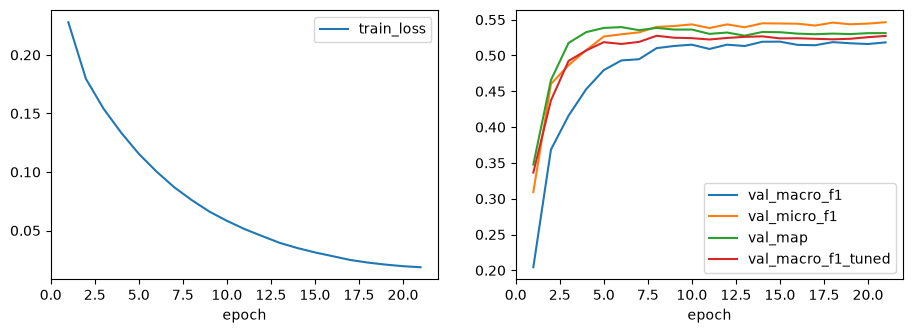

total_params                  5.173712e+06
train_time_s                  1.296028e+03
test_macro_f1                 5.122278e-01
test_micro_f1                 5.329815e-01
test_weighted_f1              5.278189e-01
test_samples_f1               5.051040e-01
test_hamming_loss             5.810699e-02
test_lrap                     6.676650e-01
test_map_macro                5.394418e-01
test_map_micro                5.774762e-01
test_subset_accuracy          2.089985e-01
test_macro_precision          5.702043e-01
test_macro_recall             4.692997e-01
test_micro_precision          5.888309e-01
test_micro_recall             4.868087e-01
test_macro_f1_27emo           5.230067e-01
test_avg_pred_cardinality     1.576681e+00
test_empty_prediction_rate    7.402032e-02
best_epoch                    1.500000e+01
dtype: float64

In [3]:
import json, matplotlib.pyplot as plt
h = pd.read_csv("results/runs/bilstm/history.csv")
display(h.round(4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
h.plot(x="epoch", y="train_loss", ax=ax[0])
h.plot(x="epoch", y=["val_macro_f1", "val_micro_f1", "val_map", "val_macro_f1_tuned"], ax=ax[1]); plt.show()
summ = json.load(open("results/runs/bilstm/summary.json"))
pd.Series({k: v for k, v in summ.items() if k.startswith("test_") or k in ("total_params", "train_time_s", "best_epoch")})